# Unidad 34 — Uso de módulos de Python

Semana 5 · Clase 2 · Fuente: PDF parte 2, págs. 4–74

[Índice de la semana](../semana-05.ipynb) | [Anterior](../clase-1-programacion-dinamica-y-backtracking/u33-backtracking.ipynb) | [Siguiente](u35-series-de-pandas.ipynb)

In [1]:
def verificar(descripcion, obtenido, esperado):
    """Compara el resultado de un ejercicio con el esperado e informa sin detener el notebook."""
    if obtenido == esperado:
        print(f"Correcto: {descripcion}")
    else:
        print(f"Incorrecto: {descripcion}. Se esperaba {esperado!r} y se obtuvo {obtenido!r}")

## Objetivos de la unidad

Según el PDF (págs. 5–7):

- Explicar por qué los módulos agrupan clases, funciones, variables y código de ejecución, y por qué son necesarios.
- Consultar la documentación de un módulo y descifrar cómo separar y utilizar las funciones, clases y parámetros que contiene.
- Elegir y usar de forma adecuada las sentencias `import`, `from` y `as`.
- Generar enteros y números reales aleatorios con el módulo `random` cuando se necesitan datos de prueba sin especificar.
- Convertir y generar valores para una fecha y hora concretas con el módulo `datetime`.
- Utilizar el módulo estándar y el módulo externo de Python, y la biblioteca estándar más usada.
- Crear módulos propios y usarlos desde otro código.
- Traer un módulo completo, o solo algunas de sus funciones o clases, y usarlas en el código.

Conceptos previos que el PDF da por sabidos: usar funciones de Python y usar clases de Python.

**Palabras clave del PDF:** módulo, importar, módulo estándar, módulo externo, al azar (`random`), instalar, `pip`, `datetime`.

**Vocabulario del docente:** **Módulo**: archivo `.py` que agrupa funciones, clases y variables; puede ser estándar o externo.

**Referencia:** PDF parte 2, págs. 4–7

## Contexto

El PDF plantea la unidad con una misión: **crear un juego de dados** en el que el ordenador y el usuario se turnan para lanzar un número fijo de dados y gana quien obtenga el total más alto. Cada uno tiene una oportunidad de volver a tirar y decide qué dados conserva y cuáles vuelve a lanzar.

El problema tiene dos ingredientes que Python no resuelve con lo básico del lenguaje: el **azar** (en lugar de decidir un valor, se deja que el ordenador elija algo al azar) y las **pausas** para simular que el ordenador "piensa". Ambos viven en módulos de la biblioteca estándar (`random` y `time`). La misión sirve además para practicar la definición de funciones propias que nombran un bloque de código y lo reutilizan.

**Referencia:** PDF parte 2, págs. 8–9

## 1. ¿Qué es un módulo?

Un **módulo** permite agrupar, gestionar y utilizar lógicamente el código de Python. Normalmente un archivo `.py` se convierte en un módulo. Dentro se pueden definir **funciones, clases y variables**, y también puede incluir código de ejecución. En pocas palabras, es un archivo de código.

Se divide en dos tipos:

- **Módulo estándar:** viene incorporado en Python (`os`, `sys`, `math`, `random`, `datetime`, `json`, `csv`, `sqlite3`). Se instala junto con Python; no hace falta memorizar su contenido porque se consulta en la biblioteca estándar: <https://docs.python.org/3/library/>.
- **Módulo externo:** lo fabrica un tercero (`pandas`, `numpy`, `matplotlib`, `scipy`, `flask`, `tensorflow`, `keras`). Hay que **instalarlo** antes de usarlo. La forma más recomendada y segura es `pip`, que viene incluido en el instalador de Python desde la versión 3.4.

Para usar un módulo se **importa** con `import`, uno o varios a la vez:

```python
import modulo            # un solo módulo
import modulo1, modulo2  # varios módulos
```

Después de importarlo, se accede a su contenido con la notación de punto: `NombreMódulo.Variable`, `NombreMódulo.NombreFunción()` y `NombreMódulo.Clase()`.

**Clave:** un módulo es un archivo `.py`; estándar = ya incluido en Python; externo = hay que instalarlo con `pip`.

**Referencia:** PDF parte 2, págs. 10–11

In [2]:
# Un módulo es un objeto: tiene nombre, archivo y contenido que se puede explorar
import math

print(type(math))
print(math.__name__)
print(math.pi)            # variable del módulo
print(math.sqrt(16))      # función del módulo
print([nombre for nombre in dir(math) if nombre in ("sin", "cos", "tan", "floor", "ceil", "pi")])

<class 'module'>
math
3.141592653589793
4.0
['ceil', 'cos', 'floor', 'pi', 'sin', 'tan']


## 2. Módulo estándar: `math` y la sentencia `import`

Como la biblioteca estándar está incorporada, no requiere instalación: basta con importarla. El PDF usa el módulo `math` (funciones matemáticas) y calcula el seno de 1 con la forma `NombreDelMódulo.NombreDeFunción()`. La lista completa de funciones está en <https://docs.python.org/3/library/math.html>.

**Referencia:** PDF parte 2, pág. 12

In [3]:
import math

# Se usa en la forma NombreDelModulo.NombreDeFuncion()
print(math.sin(1))

0.8414709848078965


## 3. Módulo externo: buscar, instalar e importar

Los módulos externos se buscan en el repositorio **PyPI** (<https://pypi.org/>). En la página de detalle de cada biblioteca aparece el comando de instalación (`pip install nombre`), que se copia y se ejecuta en la terminal. El PDF lo hace en el *Anaconda prompt*, **después de activar el entorno virtual** que se está usando, y muestra la instalación de una biblioteca llamada `chart`:

```bash
pip install chart
```

Luego se importa con `import` y se usa. El PDF ilustra con `chart.histogram(x)`, que imprime un histograma hecho con caracteres.

Si se ejecuta el código y aparece `ModuleNotFoundError: No module named 'chart'`, el mensaje indica que **la biblioteca no está instalada** (o que está en otro entorno virtual). El PDF advierte que es un error muy frecuente en principiantes. El notebook siguiente reproduce ese error de forma controlada.

**Referencia:** PDF parte 2, págs. 14–18

In [4]:
# En este entorno la biblioteca "chart" del PDF no está instalada: se captura el error y se muestra el mensaje
try:
    import chart
    x = [1, 2, 4, 3, 3, 1, 7, 9, 9, 1, 3, 2, 1, 2]
    chart.histogram(x)
except ModuleNotFoundError as error:
    print("ModuleNotFoundError:", error)
    print("Solución: instalar la biblioteca en el entorno activo con pip install chart")

ModuleNotFoundError: No module named 'chart'
Solución: instalar la biblioteca en el entorno activo con pip install chart


**Ampliación (no está en el PDF):** cómo comprobar si un módulo está instalado, sin importarlo, y qué versión tiene. `importlib.util.find_spec` devuelve `None` cuando el módulo no se encuentra; `importlib.metadata.version` informa la versión de un paquete instalado. En este curso se usa `uv`, que gestiona el entorno de cada proyecto: `uv add nombre` (o `uv pip install nombre`) cumple el papel de `pip install` del PDF.

In [5]:
import importlib.util
import importlib.metadata

for nombre in ["math", "random", "pandas", "matplotlib", "chart"]:
    instalado = importlib.util.find_spec(nombre) is not None
    print(f"{nombre:<12} instalado: {instalado}")

# Versión de dos módulos externos del curso (la salida depende del entorno)
for paquete in ["pandas", "matplotlib"]:
    print(paquete, importlib.metadata.version(paquete))

math         instalado: True
random       instalado: True
pandas       instalado: True
matplotlib   instalado: True
chart        instalado: False
pandas 3.1.0
matplotlib 3.11.2


**Error común:** olvidar instalar el módulo externo, o instalarlo en un entorno distinto de aquel donde se ejecuta el código. El síntoma es `ModuleNotFoundError`.

**Para el quiz:** el comando de instalación es `pip install nombre`; los módulos estándar no se instalan; los externos se buscan en PyPI.

## 4. Crear un módulo propio y ponerlo en funcionamiento

Además de importar módulos ajenos, cualquier archivo `.py` propio puede importarse como módulo. Importarlo ejecuta su código de nivel superior, y las funciones definidas quedan disponibles con `modulo.funcion()`. El PDF lo practica con el cálculo de fondos para un hospital:

> Se venden entradas para un evento benéfico. Cada participante abona `5t + 3`, donde `t` es el número de entradas que compra.

El primer archivo se guarda como `fund_cal.py` y define `fund(t)`. El segundo programa importa el módulo (**sin escribir la extensión `.py`**), pide el número de personas y calcula el total. El PDF muestra el archivo con tres nombres distintos: `fund_cal.py` al guardarlo, `import donate` en la importación y `donar.py` en la explicación.

**Nota sobre el PDF:** (1) el cuerpo de la función aparece como `return t5+3`, que en Python no es la fórmula `5t + 3`; la expresión correcta es `5 * t + 3`. (2) El nombre del módulo es inconsistente entre diapositivas (`fund_cal`, `donate`, `donar`); aquí se usa `fund_cal` en todo el ejemplo. (3) El código del PDF llama `fund_cal.fund(t)` con un solo valor `t`, y el enunciado habla de varias personas; se muestra también una versión que suma las entradas de cada persona.

Para no ensuciar el repositorio, los archivos `.py` de esta unidad se escriben en una **carpeta temporal** que se agrega a `sys.path` (la lista de carpetas donde Python busca módulos).

In [6]:
import sys
import tempfile
from pathlib import Path

# Carpeta temporal donde se crean los módulos de ejemplo
carpeta = Path(tempfile.mkdtemp(prefix="u34_"))
sys.path.insert(0, str(carpeta))

# Módulo 1: fund_cal.py (cálculo de fondos, fórmula 5t + 3)
(carpeta / "fund_cal.py").write_text(
    "# Guarda este archivo con el nombre fund_cal.py\n"
    "def fund(t):\n"
    "    return 5 * t + 3\n"
)

# Módulo 2: cal_n.py (suma de 1 hasta n, de dos maneras)
(carpeta / "cal_n.py").write_text(
    "# Guarda este archivo con el nombre cal_n.py\n"
    "\n"
    "def sum_n(n):\n"
    "    return n * (n + 1) // 2\n"
    "\n"
    "def sum_n2(n):\n"
    "    t = 0\n"
    "    for i in range(1, n + 1):\n"
    "        t = t + i\n"
    "    return t\n"
)
print(sorted(p.name for p in carpeta.iterdir()))

['cal_n.py', 'fund_cal.py']


In [7]:
import fund_cal   # sin la extensión .py

def main(t):
    """Versión no interactiva de la actividad: recibe t en lugar de pedirlo con input()."""
    total = fund_cal.fund(t)
    print("Importe total de la donación:", total)
    return total

main(4)   # 5 * 4 + 3 = 23

# Versión con varias personas: cada una compra un número distinto de entradas
entradas_por_persona = [1, 2, 3]
print("Total del evento:", sum(fund_cal.fund(t) for t in entradas_por_persona))

# Para usarlo de forma interactiva, quita el comentario de la siguiente línea
# main(int(input("Introduzca el número de entradas compradas: ")))

Importe total de la donación: 23
Total del evento: 39


El segundo ejemplo del PDF importa un archivo `cal_n.py` con dos funciones y las llama desde un `main()`. Explicación del PDF:

- `cal_n.py` define `sum_n(n)`, que devuelve `n * (n + 1) // 2` (fórmula de Gauss), y `sum_n2(n)`, que suma `1 + 2 + ... + n` con un bucle.
- El programa principal importa `cal_n`, define `main()`, lee `n`, llama `cal_n.sum_n(n)` y `cal_n.sum_n2(n)`, y al final invoca `main()` para que se ejecute.

**Referencia:** PDF parte 2, págs. 19–22

In [8]:
import cal_n

def main(n):
    """Versión no interactiva: recibe n en lugar de pedirlo con input()."""
    sum_v = cal_n.sum_n(n)
    print("La suma desde 1 hasta", n, "es: ", sum_v)

    sum_vv = cal_n.sum_n2(n)
    print("La suma consecutiva desde 1 hasta", n, "es: ", sum_vv)

main(100)

# Para usarlo de forma interactiva, quita el comentario de la siguiente línea
# main(int(input("Introduzca un número deseado para el cálculo : ")))

La suma desde 1 hasta 100 es:  5050
La suma consecutiva desde 1 hasta 100 es:  5050


**Ampliación (no está en el PDF):** dos detalles sobre módulos propios.

- Python guarda cada módulo importado en `sys.modules`; un segundo `import` no vuelve a ejecutar el archivo. Si se modifica el `.py` y se quiere recargar, se usa `importlib.reload(modulo)`.
- Un archivo puede distinguir si se ejecuta como programa o se importa con `if __name__ == "__main__":`. Dentro de un módulo importado, `__name__` vale el nombre del módulo; si se ejecuta directamente, vale `"__main__"`. Así el código de prueba no se ejecuta al importar.

In [9]:
import importlib
import sys

print("cal_n ya está en sys.modules:", "cal_n" in sys.modules)
print("__name__ dentro del módulo:", cal_n.__name__)

# Se reescribe el archivo y se recarga para ver el cambio
(carpeta / "cal_n.py").write_text("def sum_n(n):\n    return -1\n")
importlib.reload(cal_n)
print("tras recargar, sum_n(10) =", cal_n.sum_n(10))

# Se restaura el módulo original para el resto de la unidad
(carpeta / "cal_n.py").write_text(
    "def sum_n(n):\n    return n * (n + 1) // 2\n\n"
    "def sum_n2(n):\n    t = 0\n    for i in range(1, n + 1):\n        t = t + i\n    return t\n"
)
importlib.reload(cal_n)
print("restaurado, sum_n(10) =", cal_n.sum_n(10))

cal_n ya está en sys.modules: True
__name__ dentro del módulo: cal_n
tras recargar, sum_n(10) = -1
restaurado, sum_n(10) = 55


**Clave:** el archivo se importa con su nombre **sin `.py`**; debe estar en una carpeta incluida en `sys.path` (por ejemplo, la misma que el programa).

**Error común:** escribir `import fund_cal.py` (con la extensión): Python interpreta `fund_cal` como paquete y busca `py` dentro. Otro error es nombrar el archivo igual que un módulo estándar (por ejemplo `random.py`), que oculta al estándar.

## 5. La sentencia `from`

Un módulo contiene muchas variables y funciones y casi nunca se usan todas. Con `from` se trae solo lo necesario:

```python
from Módulo import NombreFunción
from Módulo import NombreClase
from Módulo import NombreVariable
```

Con `from math import sin`, ya no se escribe el nombre del módulo delante: `sin(1)` en lugar de `math.sin(1)`. Se pueden traer varios nombres separados por comas: `from math import sin, cos, tan`. La forma `from NombreModulo import *` trae **todo** el contenido del módulo.

Otras funciones de `math` que el PDF muestra: `floor()` redondea hacia abajo al entero más cercano (`floor(3.2)` da `3`, descartando el decimal) y `ceil()` redondea hacia arriba (`ceil(4.6)` da `5`).

**Referencia:** PDF parte 2, págs. 23–25

In [10]:
from math import sin
print(sin(1))

from math import sin, cos, tan
print(sin(1), cos(1), tan(1))

from math import floor, ceil
print(floor(3.2))   # 3
print(ceil(4.6))    # 5

0.8414709848078965
0.8414709848078965 0.5403023058681398 1.557407724654902
3
5


La forma `from math import *` del PDF trae todos los nombres públicos de `math`. Para no contaminar el espacio de nombres de este notebook, el ejemplo siguiente la ejecuta en un diccionario aparte.

**Ampliación (no está en el PDF):** `from modulo import *` se desaconseja en programas reales porque puede **sobrescribir** nombres propios sin avisar y hace difícil saber de dónde viene cada función. Es preferible `import modulo` o `from modulo import nombre`.

In [11]:
# from math import * ejecutado en un espacio de nombres aparte
espacio = {}
exec("from math import *", espacio)

nombres = [n for n in espacio if not n.startswith("__")]
print("Cantidad de nombres traídos:", len(nombres))
print("sin(1) sin prefijo:", eval("sin(1)", espacio))

# Ejemplo del riesgo: la importación con * sobrescribe un nombre propio
espacio = {"pow": "mi variable"}
exec("from math import *", espacio)
print("pow ahora es:", espacio["pow"])

Cantidad de nombres traídos: 62
sin(1) sin prefijo: 0.8414709848078965
pow ahora es: <built-in function pow>


**Clave:** `from modulo import nombre` evita escribir el prefijo; `import modulo` mantiene claro el origen.

**Error común:** después de `from math import sin`, escribir `math.sin(1)` falla con `NameError`, porque `math` no quedó importado; solo se trajo `sin`.

In [12]:
# En un espacio de nombres limpio, solo se trae sin
espacio = {}
exec("from math import sin", espacio)
try:
    exec("print(math.sin(1))", espacio)
except NameError as error:
    print("NameError:", error)

NameError: name 'math' is not defined


## 6. La sentencia `as`

Cuando el nombre de un módulo es largo, o dos bibliotecas usan el mismo nombre, se le asigna un **alias** con `as`:

```python
import NombreMódulo as Alias
from Módulo import Variable as Nombre1, Función as Nombre2, Clase as Nombre3
```

El PDF importa `math as m` y usa `m.sin(1)` y `m.floor(2.7)`; después trae funciones con alias, `from math import sin as s, cos as c`, y calcula `s(1)` y `c(1)`.

**Nota sobre el PDF:** en la diapositiva 27 el patrón muestra `from Módulo import Variable as Nombre1, ...` con los tres tipos de nombre; en la práctica se usa un alias por cada nombre importado, separados por comas.

**Referencia:** PDF parte 2, págs. 26–27

In [13]:
import math as m
print(m.sin(1))
print(m.floor(2.7))     # 2

from math import sin as s, cos as c
print(s(1))
print(c(1))

0.8414709848078965
2
0.8414709848078965
0.5403023058681398


**Ampliación (no está en el PDF):** los alias convencionales de las bibliotecas externas que se usan en este curso son `import pandas as pd`, `import numpy as np` e `import matplotlib.pyplot as plt`. Seguir la convención hace el código más legible para otras personas.

**Clave:** el alias solo cambia el nombre local; el módulo es el mismo.

**Para el quiz:** `import X as Y` y `from X import a as b` son las dos formas de usar `as`.

## 7. Biblioteca estándar: el módulo `random`

El módulo `random` genera números aleatorios y permite muestrear partes de una lista. **Aleatorio** significa que el resultado es impredecible cada vez; por ejemplo, al tirar un dado se selecciona un número al azar del 1 al 6.

### 7.1 `random.random()`

Devuelve un número real (*float*) al azar tal que `0 <= N < 1`. Cada ejecución da un valor distinto; el PDF lo llama 10 veces dentro de un bucle y obtiene 10 números distintos.

**Nota sobre el PDF:** el texto dice "[0,0, 1,0]" (traducción de `[0.0, 1.0)`); es un intervalo **cerrado a la izquierda y abierto a la derecha**: el 0 puede salir, el 1 no.

**Ampliación (no está en el PDF):** para que un ejemplo con azar sea reproducible se fija la **semilla** con `random.seed(valor)`: con la misma semilla se obtiene la misma secuencia. Los ejemplos de esta unidad usan semilla para que la salida sea estable; en un programa real no se fija.

In [14]:
import random

random.seed(34)            # semilla fija: la salida es siempre la misma
i = 0
for i in range(10):
    a = random.random()    # float entre 0 (incluido) y 1 (excluido)
    print(a)

0.5289353829404123
0.5857468547498617
0.8433262052335756
0.8986446412645931
0.8821865274686768
0.3646958019925076
0.948840439800687
0.4240745302698914
0.3061837653900229
0.0945328964594655


### 7.2 `random.sample()` y `random.choice()`

- `random.sample(colección, k)` extrae `k` elementos distintos **sin repetición**. Acepta lista, tupla, conjunto o rango (en conjuntos, desde Python 3.11 hay que pasar una secuencia: ver nota).
- `random.choice(colección)` extrae **un** elemento cualquiera de una secuencia, sin indicar cuántas muestras.

El PDF toma 6 muestras de una lista `data` de 1 a 15 y elige un perro al azar de una tupla de razas.

**Nota sobre el PDF:** el PDF indica que `sample` también admite un conjunto. En Python 3.11 o posterior eso es un error (`TypeError`): hay que convertir el conjunto en lista o tupla. El ejemplo lo demuestra.

**Referencia:** PDF parte 2, págs. 28–30

In [15]:
import random
random.seed(34)

data = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15]
a = random.sample(data, 6)      # 6 muestras sin repetición
print(a)

dog_list = ('Labrador Retriever', 'German Shepherd', 'Bulldog', 'Beagle', 'Yorkshire Terrier')
my_lovely_dog = random.choice(dog_list)
print(my_lovely_dog)

print(random.random())          # un float entre 0 y 1

[9, 6, 10, 1, 4, 12]
Beagle
0.3646958019925076


In [16]:
# Nota sobre el PDF: sample() sobre un conjunto falla en Python 3.11 o posterior
import random
conjunto = {1, 2, 3, 4, 5}
try:
    print(random.sample(conjunto, 2))
except TypeError as error:
    print("TypeError:", error)
print("Corregido:", random.sample(sorted(conjunto), 2))

TypeError: Population must be a sequence.  For dicts or sets, use sorted(d).
Corregido: [1, 4]


### 7.3 `random.uniform(a, b)`

Devuelve un número real `N` tal que `a <= N <= b` (si `a <= b`) o `b <= N <= a` (si `b < a`). El valor final puede o no estar incluido, por el redondeo de `a + (b-a) * random()`. En resumen: un real cualquiera entre el mínimo y el máximo. (El PDF escribe `random.uniforme`, una traducción de `uniform`.)

**Referencia:** PDF parte 2, pág. 31

In [17]:
import random
random.seed(34)

x = random.uniform(1.5, 10)
y = random.uniform(10, 1.5)

print("Si a <= b, entonces a <= N <= b,", x)
print("Si b < a, entonces b <= N <= a,", y)
print("Establece devolver cualquier float en el rango donde a es el valor mínimo y b es el valor máximo.")

Si a <= b, entonces a <= N <= b, 5.995950754993505
Si b < a, entonces b <= N <= a, 5.021151734626176
Establece devolver cualquier float en el rango donde a es el valor mínimo y b es el valor máximo.


### 7.4 `random.randint(a, b)` y `random.randrange(inicio, parada, paso)`

- `random.randint(a, b)`: entero `N` con `a <= N <= b`; **ambos extremos están incluidos**.
- `random.randrange(inicio, parada, paso)`: entero al azar del rango `range(inicio, parada, paso)`; el valor `parada` **no** se incluye. Con `randrange(1, 100, 2)` solo salen impares (1, 3, 5, ..., 99).

**Nota sobre el PDF:** la diapositiva dice "(a < N < b)" para `randint`, lo que sugiere que los extremos no se incluyen. Es incorrecto: `randint(1, 6)` puede devolver 1 y 6, y por eso sirve para simular un dado. El ejemplo lo comprueba.

**Referencia:** PDF parte 2, pág. 32

In [18]:
import random
random.seed(34)

x = random.randint(1, 100)
print(x)

x = random.randrange(1, 100, 2)    # impares entre 1 y 99
print(x)

# Comprobación: randint incluye ambos extremos
tiradas = {random.randint(1, 6) for _ in range(1000)}
print("Valores posibles de un dado:", sorted(tiradas))
impares = {random.randrange(1, 10, 2) for _ in range(1000)}
print("randrange(1, 10, 2) solo da:", sorted(impares))

68
45
Valores posibles de un dado: [1, 2, 3, 4, 5, 6]
randrange(1, 10, 2) solo da: [1, 3, 5, 7, 9]


**Ampliación (no está en el PDF):** otras funciones útiles de `random`: `shuffle(lista)` desordena una lista **en el sitio**, `choices(secuencia, k=n)` elige con repetición y `random.Random(semilla)` crea un generador independiente (se usa en los ejercicios para que cada llamada sea reproducible).

In [19]:
import random
random.seed(34)

cartas = ["A", "K", "Q", "J"]
random.shuffle(cartas)                 # modifica la lista original
print(cartas)
print(random.choices(["cara", "cruz"], k=5))   # con repetición

generador = random.Random(7)           # generador propio, no afecta a random.seed global
print(generador.randint(1, 6), generador.randint(1, 6))

['K', 'A', 'J', 'Q']
['cruz', 'cruz', 'cruz', 'cara', 'cruz']
3 2


**Clave:** `random()` da un real en [0, 1); `uniform(a, b)` un real en el rango; `randint(a, b)` un entero con ambos extremos incluidos; `randrange` respeta `inicio`, `parada` (excluido) y `paso`; `sample` no repite; `choice` extrae uno.

**Error común:** creer que `randint(1, 6)` nunca devuelve 6 (sí lo devuelve), o que `randrange(1, 6)` puede devolver 6 (no puede).

**Para el quiz:** `randint(1, 6)` simula un dado; `sample(lista, k)` es muestreo sin repetición.

## 8. Biblioteca estándar: el módulo `time`

### 8.1 `time.sleep(segs)`

Es la función más usada del módulo `time`. **Pausa la ejecución** del hilo que la llama durante los segundos indicados; el argumento puede ser entero o `float`. El PDF imprime `Hello` diez veces con una pausa de 2 segundos en cada vuelta del bucle.

**Nota sobre el PDF:** el código de la diapositiva imprime el contador con `1+1`, pero la salida muestra `Hello 1` a `Hello 10`; la expresión correcta es `i+1`. Además, aquí las pausas son de centésimas de segundo para que el notebook se ejecute rápido: el comportamiento es el mismo.

**Referencia:** PDF parte 2, pág. 33

In [20]:
import time

inicio = time.perf_counter()
for i in range(10):
    print("Hello", i + 1)
    time.sleep(0.01)          # el PDF usa 2 segundos; aquí 0.01 para ir rápido
print(f"Tiempo total aproximado: {time.perf_counter() - inicio:.2f} s")

Hello 1
Hello 2
Hello 3
Hello 4
Hello 5
Hello 6
Hello 7
Hello 8
Hello 9
Hello 10
Tiempo total aproximado: 0.12 s


### 8.2 `time.time()` y `time.ctime()`

- `time.time()` devuelve la hora actual como **segundos transcurridos desde las 00:00:00 UTC del 1 de enero de 1970** (la *marca de tiempo Unix* o tiempo de época). El valor es un `float`, difícil de leer.
- `time.ctime(a)` convierte esa marca en una cadena legible, como `Thu Aug 26 10:19:23 2021`.

**Nota sobre el PDF:** el texto dice que la marca de tiempo "se expresa como un número entero", pero `time.time()` devuelve un número con decimales (la propia salida del PDF muestra `1629940763.8416274`). Para obtener un entero basta `int(time.time())`.

**Referencia:** PDF parte 2, págs. 33–34

In [21]:
import time

a = time.time()
b = time.ctime(a)
print(type(a), a)       # float; el valor depende del momento de ejecución
print(b)                # cadena legible en la hora local

# Con la marca del PDF, y en UTC para que el resultado no dependa de la zona horaria
marca = 1629940763.8416274
print(time.asctime(time.gmtime(marca)))
print("Como entero:", int(marca))
print("Época:", time.asctime(time.gmtime(0)))

<class 'float'> 1792680966.175488
Thu Oct 22 09:56:06 2026
Thu Aug 26 01:19:23 2021
Como entero: 1629940763
Época: Thu Jan  1 00:00:00 1970


### Reloj electrónico sencillo

El PDF combina `sleep` y `ctime` en un bucle: cada segundo imprime la hora. Aquí se reduce a 3 vueltas y a una pausa mínima.

In [22]:
import time

for i in range(3):
    time.sleep(0.01)            # el PDF usa time.sleep(1) y 10 vueltas
    print(time.ctime())         # la salida depende de la hora actual

Thu Oct 22 09:56:06 2026
Thu Oct 22 09:56:06 2026


Thu Oct 22 09:56:06 2026


### 8.3 `time.strftime(formato, objeto_time)`

Da formato a una fecha y hora con **códigos** que empiezan por `%`. Los principales que recoge el PDF:

| Código | Significado | Código | Significado |
|---|---|---|---|
| `%Y` | año con 4 dígitos | `%u` | día de la semana (1 = lunes ... 7 = domingo) |
| `%y` | año con 2 dígitos | `%w` | día de la semana (0 = domingo ... 6 = sábado) |
| `%m` | mes numérico (01-12) | `%H` | hora en formato 24 h (00-23) |
| `%B` / `%b` | nombre completo / abreviado del mes | `%I` | hora en formato 12 h (01-12) |
| `%d` | día del mes (01-31) | `%p` | AM o PM |
| `%A` / `%a` | nombre completo / abreviado del día | `%M` / `%S` | minutos / segundos (00-59) |
| `%c` | fecha y hora completas | `%x` / `%X` | fecha preferida / hora preferida |

Con `%y`, los valores 69 a 99 corresponden a 1969-1999 y los valores 0 a 68 a 2000-2068. Documentación: <https://docs.python.org/3/library/time.html#time.strftime>.

El segundo argumento es una estructura de tiempo: `time.gmtime()` (hora UTC) o `time.localtime()` (hora local). El PDF ejecuta los dos para imprimir la fecha con el formato `Thu, 26 Aug 2021 01:15:47 +0000`.

**Nota sobre el PDF:** (1) el formato aparece como `"%a, %d %b %Y %H:%%M:%S +0000"`; el `%%M` es un error de transcripción (`%%` imprime un `%` literal) y produce `%M` sin sustituir. El formato correcto es `"%a, %d %b %Y %H:%M:%S +0000"`. (2) La tabla pone los nombres en español (Lunes, Enero), pero la salida real está en inglés (`Thu`, `Aug`): `%a`, `%A`, `%b` y `%B` dependen de la **configuración regional** del sistema; por defecto, Python usa inglés. (3) `%x` y `%X` también dependen de la región.

**Referencia:** PDF parte 2, págs. 35–37

In [23]:
import time
from time import gmtime, localtime, strftime

# Formato del PDF, corregido (%H:%M:%S). Se usa una marca fija para que la salida sea estable.
marca = 1629940547
print(strftime("%a, %d %b %Y %H:%M:%S +0000", gmtime(marca)))

# Con la hora actual la salida cambia en cada ejecución
print(strftime("%a, %d %b %Y %H:%M:%S +0000", gmtime()))
print(strftime("%a, %d %b %Y %H:%M:%S +0000", localtime()))

# Error del PDF: con %% se imprime un % literal y la parte de minutos no se sustituye
print(strftime("%H:%%M:%S", gmtime(marca)))

Thu, 26 Aug 2021 01:15:47 +0000
Thu, 22 Oct 2026 14:56:06 +0000
Thu, 22 Oct 2026 09:56:06 +0000
01:%M:47


In [24]:
import time
momento = time.gmtime(1629940547)       # jueves 26 de agosto de 2021, 01:15:47 UTC

for codigo in ["%Y", "%y", "%m", "%B", "%b", "%d", "%A", "%a", "%w", "%u", "%H", "%I", "%p", "%M", "%S"]:
    print(f"{codigo}: {time.strftime(codigo, momento)}")

%Y: 2021
%y: 21
%m: 08
%B: August
%b: Aug
%d: 26
%A: Thursday
%a: Thu
%w: 4
%u: 4
%H: 01
%I: 01
%p: AM
%M: 15
%S: 47


**Clave:** `sleep` pausa; `time()` da segundos desde 1970 (UTC); `ctime` lo hace legible; `strftime` formatea con códigos `%`.

**Error común:** dejar `%%` en el formato o escribir el código en minúscula cuando corresponde mayúscula (`%m` es mes; `%M` es minutos).

**Para el quiz:** la marca de tiempo Unix cuenta segundos desde el 1 de enero de 1970 a las 00:00:00 UTC.

## 9. Biblioteca estándar: el módulo `datetime`

Es el módulo para fechas y horas y se usa a menudo para crear formatos de fecha.

### 9.1 `datetime.date.today()`

Devuelve la **fecha actual** (sin hora) como un objeto `date`. Con los atributos `.year`, `.month` y `.day` se separa cada parte.

### 9.2 `datetime.datetime.now()`

Devuelve la fecha **y la hora** actuales como un objeto `datetime`. Además de `year`, `month` y `day`, tiene `hour`, `minute`, `second` y `microsecond`.

**Referencia:** PDF parte 2, págs. 38–41

In [25]:
import datetime

today = datetime.date.today()      # la fecha cambia según el día de ejecución
print(today)
print(today.year, "year")
print(today.month, "month")
print(today.day, "day")

2026-10-22
2026 year
10 month
22 day


In [26]:
import datetime

now = datetime.datetime.now()      # la salida depende del momento de ejecución
print(now)
print(now.year, "year")
print(now.month, "month")
print(now.day, "day")
print(now.hour, "hour")
print(now.minute, "minute")
print(now.second, "second")

2026-10-22 09:56:06.223652
2026 year
10 month
22 day
9 hour
56 minute
6 second


**Ampliación (no está en el PDF):** como `today()` y `now()` cambian en cada ejecución, para ejemplos reproducibles se construye una fecha concreta con `datetime.datetime(año, mes, día, hora, minuto, segundo)` o `datetime.date(año, mes, día)`. También se puede formatear con `strftime` y leer texto con `strptime`.

In [27]:
from datetime import date, datetime

ejemplo = datetime(2021, 8, 26, 13, 58, 29)
print(ejemplo)
print(ejemplo.strftime("%d/%m/%Y %H:%M"))          # formatear: objeto a texto
print(datetime.strptime("26/08/2021 13:58", "%d/%m/%Y %H:%M"))   # leer: texto a objeto
print(ejemplo.date(), "|", ejemplo.weekday(), "(lunes = 0, jueves = 3)")
print(date(2024, 2, 29).isoformat())

2021-08-26 13:58:29
26/08/2021 13:58
2021-08-26 13:58:00
2021-08-26 | 3 (lunes = 0, jueves = 3)
2024-02-29


### 9.3 `datetime.timedelta`: la diferencia entre dos fechas

Un `timedelta` es un objeto que representa una **duración**, la diferencia entre dos fechas o momentos; mide "cuánto tiempo pasa" entre un punto A y un punto B. El PDF lo explica así: una fecha específica es "25 de agosto de 2024"; un `timedelta` es "3 días y 5 horas".

- **Recibe** unidades distintas (días, horas, minutos, segundos...).
- **Normaliza** todo a una forma estándar (días, segundos, microsegundos).
- **Permite** sumar y restar tiempo a fechas, comparar duraciones y calcular diferencias.

Casos de uso del PDF: (1) calcular fechas futuras o pasadas, (2) validar plazos y vencimientos, (3) calcular edades.

**Referencia:** PDF parte 2, págs. 42–43

In [28]:
from datetime import datetime, timedelta

# Caso 1 del PDF: fechas futuras o pasadas (con una fecha fija para que el resultado sea estable)
hoy = datetime(2021, 8, 26, 12, 0)
en_una_semana = hoy + timedelta(weeks=1)
hace_30_dias = hoy - timedelta(days=30)
print(en_una_semana)
print(hace_30_dias)

# Con la hora real: el resultado cambia cada día
print(datetime.now() + timedelta(weeks=1))

2021-09-02 12:00:00
2021-07-27 12:00:00
2026-10-29 09:56:06.229241


**Nota sobre el PDF:** los ejemplos 2 y 3 son correctos como técnica, pero tienen dos defectos.

- *Plazos:* usa `datetime(2024, 12, 31)` como fecha límite; hoy esa fecha ya pasó, el `timedelta` resulta **negativo** y la condición `tiempo_restante.days < 30` siempre es verdadera, aunque el plazo no esté "próximo a vencer" sino vencido. Hay que tratar el caso negativo. Además, `.days` de un `timedelta` negativo es el piso, no la diferencia exacta.
- *Edad:* `edad_exacta.days // 365` es una **aproximación**: ignora los años bisiestos (un año tiene 365 o 366 días) y puede fallar un día alrededor del cumpleaños. Para una edad exacta se compara el mes y el día.

In [29]:
from datetime import datetime

# Caso 2 del PDF con una fecha de referencia fija y el caso "vencido" tratado
ahora = datetime(2024, 12, 10)
fecha_limite = datetime(2024, 12, 31)
tiempo_restante = fecha_limite - ahora
print(tiempo_restante)
if tiempo_restante.days < 0:
    print("El plazo ya venció")
elif tiempo_restante.days < 30:
    print("Plazo próximo a vencer")

# Caso 3 del PDF: edad aproximada con days // 365
nacimiento = datetime(1990, 5, 15)
referencia = datetime(2024, 5, 14)
print("Aproximada:", (referencia - nacimiento).days // 365)

# Edad exacta: se resta un año si todavía no se llegó al cumpleaños
exacta = referencia.year - nacimiento.year - ((referencia.month, referencia.day) < (nacimiento.month, nacimiento.day))
print("Exacta:", exacta)

21 days, 0:00:00
Plazo próximo a vencer
Aproximada: 34
Exacta: 33


### Argumentos de `timedelta`

Firma: `datetime.timedelta(days=0, seconds=0, microseconds=0, milliseconds=0, minutes=0, hours=0, weeks=0)`. (El PDF la muestra con nombres traducidos — `días`, `segundos`... — pero en Python los nombres de los argumentos van **en inglés**.)

- Todos son opcionales y valen 0 por defecto.
- Aceptan enteros o reales, positivos o negativos.
- Conversiones: 1 milisegundo = 1000 microsegundos; 1 minuto = 60 segundos; 1 hora = 3600 segundos; 1 semana = 7 días.

El ejemplo del PDF suma `50 días + 2 semanas`, `27 s + 29000 ms + 5 min + 8 h` y `10 µs`, y obtiene `64 days, 8:05:56.000010`. Luego busca la fecha que está 30 días después del 3 de mayo de 2000.

**Referencia:** PDF parte 2, págs. 44–46

In [30]:
from datetime import timedelta, datetime

delta = timedelta(
    days=50,
    seconds=27,
    microseconds=10,
    milliseconds=29000,
    minutes=5,
    hours=8,
    weeks=2
)
print(delta)                          # 64 days, 8:05:56.000010
print(delta.days, delta.seconds, delta.microseconds)
print(delta.total_seconds())          # Ampliación: toda la duración en segundos

# 30 días después del 3 de mayo de 2000
d = datetime(2000, 5, 3)
delta = timedelta(days=30)
print(d + delta)                      # 2000-06-02 00:00:00

64 days, 8:05:56.000010
64 29156 10
5558756.00001
2000-06-02 00:00:00


### 9.4 `datetime.replace()`

Crea una copia de un objeto `datetime` con **algunos elementos cambiados**: `replace(year=, month=, day=, hour=, minute=, second=, microsecond=)`. El PDF cambia el mes a diciembre y el día a 30.

**Ampliación (no está en el PDF):** `replace` no modifica el original (los objetos `datetime` son inmutables) y falla si el resultado no es una fecha válida (por ejemplo, 30 de febrero).

**Referencia:** PDF parte 2, pág. 47

In [31]:
from datetime import datetime

now = datetime(2021, 8, 26, 15, 18, 41, 392983)    # el PDF usa datetime.now(); aquí fija para estabilidad
print(now)

replace_time = now.replace(month=12, day=30)
print(replace_time)
print(now)                                         # el original no cambia

try:
    now.replace(month=2, day=30)
except ValueError as error:
    print("ValueError:", error)

2021-08-26 15:18:41.392983
2021-12-30 15:18:41.392983
2021-08-26 15:18:41.392983
ValueError: day 30 must be in range 1..28 for month 2 in year 2021


**Clave:** `date` = solo fecha; `datetime` = fecha y hora; `timedelta` = duración; la resta de dos fechas da un `timedelta` y sumar un `timedelta` a una fecha da otra fecha.

**Error común:** confundir `import datetime` (el módulo) con `from datetime import datetime` (la clase). Con la primera forma se escribe `datetime.datetime.now()`; con la segunda, `datetime.now()`.

**Para el quiz:** los argumentos de `timedelta` se escriben en inglés (`days`, `hours`...) y 1 semana = 7 días.

## 10. Biblioteca estándar: el módulo `os`

Contiene funciones relacionadas con el **sistema operativo**. Permite crear carpetas o ver la lista de archivos de una carpeta:

- `os.mkdir("nombre")`: crea una carpeta.
- `os.rmdir("nombre")`: elimina una carpeta (debe estar vacía).
- `os.getcwd()`: devuelve la ruta actual de trabajo.
- `os.listdir()`: lista los archivos y directorios de la carpeta actual.

El PDF muestra `os.getcwd()` (una ruta de Windows del equipo del autor) y `os.listdir()` (con un `.ipynb_checkpoints`, un `01.ipynb`, una carpeta `data` y el notebook de la unidad).

**Referencia:** PDF parte 2, pág. 48

In [32]:
import os

# Se trabaja dentro de la carpeta temporal para no crear nada en el repositorio
original = os.getcwd()
os.chdir(carpeta)
try:
    print("La carpeta actual es la temporal:", os.path.basename(os.getcwd()).startswith("u34_"))
    os.mkdir("data")
    print(sorted(os.listdir()))
    os.rmdir("data")
    print(sorted(os.listdir()))
finally:
    os.chdir(original)         # se vuelve a la carpeta del notebook
print("Restaurada:", os.getcwd() == original)

La carpeta actual es la temporal: True
['__pycache__', 'cal_n.py', 'data', 'fund_cal.py']
['__pycache__', 'cal_n.py', 'fund_cal.py']
Restaurada: True


**Ampliación (no está en el PDF):** para rutas y archivos, `pathlib.Path` ofrece una interfaz orientada a objetos más cómoda que `os` y `os.path`; este notebook la usa para crear los módulos de ejemplo.

In [33]:
# Limpieza de la carpeta temporal: se quitan los módulos de ejemplo de sys.modules y de sys.path
import shutil, sys

for nombre in ["fund_cal", "cal_n"]:
    sys.modules.pop(nombre, None)
sys.path.remove(str(carpeta))
shutil.rmtree(carpeta)
print("Carpeta temporal eliminada:", not carpeta.exists())

Carpeta temporal eliminada: True


## Proyecto de la unidad

### Misión: crear un juego de dados

**Problema (PDF):** el ordenador y el usuario se turnan para lanzar un número fijo de dados y gana quien obtenga el total más alto. Cada uno tiene **una** oportunidad de volver a tirar y decide qué dados conserva (`-`) y cuáles vuelve a lanzar (`r`). La misión pone en práctica el azar (`random`) y las pausas (`time.sleep`), y la definición de funciones propias que nombran un bloque de código para reutilizarlo.

**Plan de programación (los 19 pasos del PDF, agrupados):**

1. Pedir el número de dados y convertirlo de cadena a entero (paso 1); pedir pulsar una tecla para comenzar (paso 2).
2. Importar `random` (paso 3) y definir `roll_dice(n)`: crea una lista vacía y agrega `n` números aleatorios entre 1 y 6 (pasos 4–5).
3. Lanzar los dados del usuario y mostrar la primera tirada (paso 6).
4. Leer las opciones del usuario (conservar o volver a tirar cada dado) y validar que la cantidad coincida con la de dados (paso 7).
5. Importar `time` (paso 8) y definir `roll_again(choices, dice_list)`: muestra un mensaje, pausa, sustituye por un número nuevo cada dado marcado con `r` y vuelve a pausar (pasos 9–10).
6. Volver a tirar según las opciones del usuario y mostrar la nueva tirada (paso 11).
7. Turno del ordenador: lanzar sus dados (paso 12), definir su estrategia (pasos 13–14: `r` si el dado es menor de 5; `-` si es 5 o 6), aplicarla y volver a tirar (pasos 15–16).
8. Definir `find_winner(cdice_list, udice_list)`: suma con `sum()`, muestra los totales y declara ganador, o empate (pasos 17–18) y llamarla al final (paso 19).

**Referencia:** PDF parte 2, págs. 49–62

#### Pasos 3–5: importar `random` y definir `roll_dice`

Las pausas del PDF son de 3 segundos. Aquí se usa la constante `PAUSA`, de centésimas de segundo, para que el notebook corra rápido; basta cambiar su valor a `3` para el comportamiento original.

**Nota sobre el PDF:** los nombres del texto (`tirar_el_dado`, `lanzar_dados`, `tirar_otra_vez`, `estrategia_de_la_computadora`, `ordenador_estrategia`, `encontrar_ganador`) son traducciones automáticas y no coinciden entre diapositivas. Los nombres reales están en el código de las diapositivas finales: `roll_dice`, `roll_again`, `computer_strategy1`/`computer_strategy2` y `find_winner`; aquí se usan esos.

In [34]:
import random
import time

PAUSA = 0.01     # el PDF usa time.sleep(3); aquí se acorta para ejecutar rápido

def roll_dice(n):
    dice = []                              # empieza con una lista vacía de dados
    # añade números aleatorios entre 1 y 6 a la lista
    for i in range(n):
        dice.append(random.randint(1, 6))
    return dice

random.seed(2026)
print(roll_dice(3))

[1, 3, 5]


#### Pasos 8–10: `roll_again` con `time.sleep`

Recorre las opciones: donde hay una `r`, el dado de esa posición se reemplaza por un número nuevo entre 1 y 6. La función **no devuelve nada** (es una función *void*): modifica la lista que recibe.

In [35]:
def roll_again(choices, dice_list):
    print('Volviendo a tirar ...')
    time.sleep(PAUSA)
    for i in range(len(choices)):
        if choices[i] == 'r':
            dice_list[i] = random.randint(1, 6)
    time.sleep(PAUSA)

random.seed(2026)
dados = roll_dice(4)
print("Antes:  ", dados)
roll_again("r-r-", dados)       # vuelve a tirar los dados 1 y 3
print("Después:", dados)

Antes:   [1, 3, 5, 5]
Volviendo a tirar ...


Después: [6, 3, 1, 5]


#### Pasos 13–14: estrategia del ordenador

El PDF define dos estrategias: `computer_strategy1(n)` vuelve a tirar **todos** los dados; `computer_strategy2(n)` vuelve a tirar solo los menores de 5 (los usa en el programa final). Ambas devuelven una cadena con `r` o `-` por dado.

**Nota sobre el PDF:** (1) `computer_strategy2(n)` lee la variable global `computer_rolls` sin recibirla como parámetro; funciona solo porque esa variable existe cuando se la llama. Aquí se pasa como argumento (`computer_strategy2(n, computer_rolls)`), que es más claro y seguro. (2) El código inicia `choices = ''` (una cadena), mientras el texto habla de una lista vacía; en el consejo del PDF, `list[ ]` no es válido (es `list()` o `[]`) y `' '` es una cadena. Para construir la elección carácter a carácter, la cadena funciona porque `choices[i]` y `len(choices)` se comportan igual en cadenas y listas.

In [36]:
def computer_strategy1(n):
    # Estrategia 1: volver a tirar todo
    print('El ordenador está pensando ...')
    time.sleep(PAUSA)
    choices = ''                       # empieza con una cadena vacía de elecciones
    for i in range(n):
        choices = choices + 'r'
    return choices

def computer_strategy2(n, computer_rolls):
    # Estrategia 2: volver a tirar si el dado es menor de 5
    print('El ordenador está pensando ...')
    time.sleep(PAUSA)
    choices = ''
    for i in range(n):
        if computer_rolls[i] < 5:
            choices = choices + 'r'
        else:
            choices = choices + '-'
    return choices

print(computer_strategy1(3))
print(computer_strategy2(4, [1, 5, 6, 4]))   # r--r

El ordenador está pensando ...
rrr
El ordenador está pensando ...
r--r


#### Pasos 17–18: `find_winner`

`sum(iterable, inicio)` devuelve la suma de los elementos de un iterable (`inicio` es opcional y se suma al resultado). `find_winner` calcula los dos totales, los muestra y compara.

In [37]:
def find_winner(cdice_list, udice_list):
    computer_total = sum(cdice_list)
    user_total = sum(udice_list)
    print('Total del ordenador:', computer_total)
    print('Total del usuario:', user_total)
    if user_total > computer_total:
        print('Gana el usuario')
    elif user_total < computer_total:
        print('Gana el ordenador')
    else:
        print('Empate')

find_winner([3, 4], [6, 5])
find_winner([6, 6], [1, 2])
find_winner([3, 3], [2, 4])

Total del ordenador: 7
Total del usuario: 11
Gana el usuario
Total del ordenador: 12
Total del usuario: 3
Gana el ordenador
Total del ordenador: 6
Total del usuario: 6
Empate


#### Programa principal completo

El PDF escribe el programa principal como código suelto (pasos 1, 2, 4, 5 y 6 de la diapositiva final). Aquí se encapsula en la función `juego_de_dados(leer=input)`, donde `leer` es la función que obtiene el texto del usuario. Por defecto es `input`, y para una ejecución no interactiva se le pasa una función que devuelve respuestas de prueba. Los textos de los avisos se tradujeron al español.

La versión no interactiva simula un usuario con 3 dados que primero escribe una elección incorrecta (`r`, de longitud 1) para mostrar la **validación**, y luego `-r-` (conserva el primero y el tercero, vuelve a lanzar el segundo).

In [38]:
def juego_de_dados(leer=input):
    # Paso 1: iniciar el juego
    number_dice = int(leer('Ingresa el número de dados: '))
    ready = leer('¿Listo para empezar? Pulsa Enter para continuar: ')

    # Paso 2: turno del usuario, primera tirada
    user_rolls = roll_dice(number_dice)
    print('Primera tirada del usuario: ', user_rolls)

    # Paso 3: elecciones del usuario, con validación de longitud
    user_choices = leer('Escribe - para conservar o r para volver a tirar cada dado: ')
    while len(user_choices) != number_dice:
        print('Debes ingresar', number_dice, 'opciones')
        user_choices = leer('Escribe - para conservar o r para volver a tirar cada dado: ')

    # Paso 4: el usuario vuelve a tirar según sus elecciones
    roll_again(user_choices, user_rolls)
    print('Nueva tirada del usuario: ', user_rolls)

    # Paso 5: turno del ordenador
    print('Turno del ordenador')
    computer_rolls = roll_dice(number_dice)
    print('Primera tirada del ordenador: ', computer_rolls)

    # Paso 6: el ordenador decide con la estrategia 2 y vuelve a tirar
    computer_choices = computer_strategy2(number_dice, computer_rolls)
    print('Elección del ordenador: ', computer_choices)
    roll_again(computer_choices, computer_rolls)
    print('Nueva tirada del ordenador: ', computer_rolls)

    # Última línea: decidir quién gana
    find_winner(computer_rolls, user_rolls)
    return computer_rolls, user_rolls

def entradas_simuladas(respuestas):
    """Devuelve una función que reemplaza a input() y responde con la lista dada."""
    pendientes = iter(respuestas)
    def leer(mensaje):
        respuesta = next(pendientes)
        print(mensaje + repr(respuesta))
        return respuesta
    return leer

random.seed(2026)
dados_ordenador, dados_usuario = juego_de_dados(entradas_simuladas(['3', '', 'r', '-r-']))

# Para usarlo de forma interactiva, quita el comentario de la siguiente línea
# juego_de_dados()

Ingresa el número de dados: '3'
¿Listo para empezar? Pulsa Enter para continuar: ''
Primera tirada del usuario:  [1, 3, 5]
Escribe - para conservar o r para volver a tirar cada dado: 'r'
Debes ingresar 3 opciones
Escribe - para conservar o r para volver a tirar cada dado: '-r-'
Volviendo a tirar ...
Nueva tirada del usuario:  [1, 5, 5]
Turno del ordenador
Primera tirada del ordenador:  [6, 1, 2]
El ordenador está pensando ...
Elección del ordenador:  -rr
Volviendo a tirar ...
Nueva tirada del ordenador:  [6, 5, 5]
Total del ordenador: 16
Total del usuario: 11
Gana el ordenador


**Resultado esperado:** el programa muestra la primera tirada del usuario, rechaza la elección de longitud incorrecta, vuelve a tirar el dado marcado, juega el ordenador con su estrategia y declara ganador o empate según los totales. Con otra semilla (o sin fijarla) el resultado cambia.

Comprobación del invariante del juego: se juegan varias partidas con semillas distintas y se verifica que cada dado sigue entre 1 y 6 y que `sum` coincide con lo que se compara.

In [39]:
import io
from contextlib import redirect_stdout

partidas_ok = True
for semilla in range(20):
    random.seed(semilla)
    with redirect_stdout(io.StringIO()):          # se oculta la salida para no llenar el notebook
        c, u = juego_de_dados(entradas_simuladas(['4', '', '-r-r']))
    partidas_ok = partidas_ok and all(1 <= d <= 6 for d in c + u) and len(c) == len(u) == 4
print("20 partidas con dados válidos:", partidas_ok)

20 partidas con dados válidos: True


**Referencia:** PDF parte 2, págs. 50–67 (pasos 1 a 19 y código finalizado)

### Programación en pareja: obra de arte creativa con `turtle`

**Resumen de la práctica (PDF):** la programación en pareja requiere preparar pautas y mecanismos (por ejemplo, turnarse para manejar el ratón) y planes de contingencia si un compañero falta; emparejar a estudiantes con habilidades similares, no necesariamente iguales; que sea un verdadero esfuerzo conjunto, no "divide y vencerás"; ofrecer incentivos; y evitar trampas explicando qué comportamientos se considerarán tales. El entorno de aprendizaje colaborativo implica trabajar juntos en las actividades.

**Q1 (PDF):** completar la obra de arte creativa mirando la documentación de `turtle`, una de las bibliotecas estándar de Python (<https://docs.python.org/3/library/turtle.html>). El código dibuja un **arco iris geométrico**: 36 hexágonos girados 10 grados entre sí, y luego 36 círculos blancos alrededor.

**Nota sobre el PDF:** el código está en las diapositivas 71 y 72 (líneas 1–15 y 16–30); se ve completo al unirlas. Las diapositivas 69–70 tienen una capa de texto mezclada (español e inglés superpuestos) que sale ilegible al copiar el texto, pero se visualizan bien como imagen. No se detectaron páginas en blanco ni dañadas en esta unidad.

**Nota sobre la ejecución:** `turtle` abre una ventana gráfica (usa la biblioteca `tkinter`), por lo que **no se puede ejecutar en un notebook sin pantalla**. El código se muestra aquí como referencia, sin ejecutar; para correrlo, guárdalo en un archivo `.py` y ejecútalo desde un equipo con entorno gráfico (agregando `turtle.done()` al final para que la ventana no se cierre sola).

```python
# make a geometric rainbow pattern
import turtle
colors = ['red', 'yellow', 'blue', 'orange', 'green', 'red']

aiden= turtle.Turtle()
turtle.bgcolor('black') # turn background black
# make 36 hexagons, each 10 degrees apart

for n in range(36):
# make hexagon by repeating 6 times
    for i in range(6):
        aiden.color(colors[i]) # pick color at position i
        aiden.forward(100)
        aiden.left(60)
    # add a turn before the next hexagon
    aiden.right(10)

# get ready to draw 36 circles
aiden.penup()
aiden.color('white')
# repeat 36 times to match the 36 hexagons
for i in range(36):
    aiden.forward(220)
    aiden.pendown()
    aiden.circle(5)
    aiden.penup()
    aiden.backward(220)
    aiden.right(10)
# hide turtle to finish the drawing
aiden.hideturtle()
```

Explicación del PDF por líneas: 1) crea un arco iris geométrico; 6) pone el fondo negro; 7) hace 36 hexágonos, cada uno girado 10 grados; 10) forma el hexágono repitiendo 6 veces; 12) elige el color en la posición `i`; 15) añade un giro antes del siguiente hexágono; 18) se prepara para dibujar 36 círculos; 21) repite 36 veces para igualar los 36 hexágonos; 29) esconde la tortuga para terminar el dibujo.

El PDF propone además abrir en IDLE el menú *Help > Turtle demo*, donde hay demostraciones (por ejemplo un reloj que usa `datetime`); la pareja elige una y la usa para cambiar la ilustración.

**Referencia:** PDF parte 2, págs. 68–74 (la pág. 68 es la portada de la sección)

**Ampliación (no está en el PDF):** como `turtle` no corre sin pantalla, la obra se **reproduce con matplotlib**. Se programa una tortuga mínima que guarda sus movimientos (posición y rumbo, con las mismas órdenes `forward`, `left`, `right`, `penup`, `pendown`, `circle`, `backward`) y luego se dibujan los segmentos y círculos. El código del dibujo es el mismo que el del PDF; solo cambia quién ejecuta las órdenes.

Esto también ilustra por qué existen los módulos: la clase `Tortuga` de abajo hace el trabajo y el programa del PDF solo la usa.

Segmentos:

 216 | círculos: 36


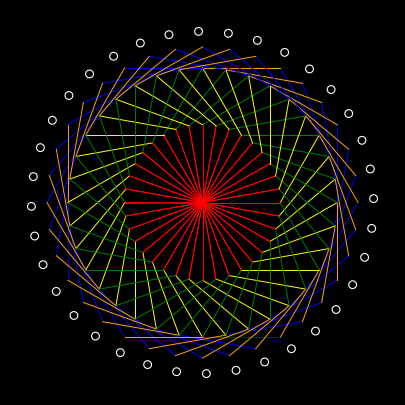

In [40]:
import math
import matplotlib.pyplot as plt
from matplotlib.patches import Circle


class Tortuga:
    """Tortuga mínima: guarda líneas y círculos en vez de abrir una ventana (reemplaza a turtle.Turtle)."""

    def __init__(self):
        self.x, self.y, self.rumbo = 0.0, 0.0, 0.0     # empieza en el origen mirando al este
        self.lapiz_abajo = True
        self.color_actual = "white"
        self.lineas = []        # (x1, y1, x2, y2, color)
        self.circulos = []      # (cx, cy, radio, color)

    def color(self, nombre): self.color_actual = nombre
    def penup(self): self.lapiz_abajo = False
    def pendown(self): self.lapiz_abajo = True
    def left(self, grados): self.rumbo += grados
    def right(self, grados): self.rumbo -= grados
    def hideturtle(self): pass

    def forward(self, distancia):
        nx = self.x + distancia * math.cos(math.radians(self.rumbo))
        ny = self.y + distancia * math.sin(math.radians(self.rumbo))
        if self.lapiz_abajo:
            self.lineas.append((self.x, self.y, nx, ny, self.color_actual))
        self.x, self.y = nx, ny

    def backward(self, distancia): self.forward(-distancia)

    def circle(self, radio):
        # turtle dibuja la circunferencia con el centro a la izquierda de la tortuga
        if self.lapiz_abajo:
            cx = self.x + radio * math.cos(math.radians(self.rumbo + 90))
            cy = self.y + radio * math.sin(math.radians(self.rumbo + 90))
            self.circulos.append((cx, cy, radio, self.color_actual))


# --- Programa del PDF, sin cambios salvo la tortuga y el fondo ---
colors = ['red', 'yellow', 'blue', 'orange', 'green', 'red']
aiden = Tortuga()

for n in range(36):
    for i in range(6):
        aiden.color(colors[i])
        aiden.forward(100)
        aiden.left(60)
    aiden.right(10)

aiden.penup()
aiden.color('white')
for i in range(36):
    aiden.forward(220)
    aiden.pendown()
    aiden.circle(5)
    aiden.penup()
    aiden.backward(220)
    aiden.right(10)
aiden.hideturtle()

print("Segmentos:", len(aiden.lineas), "| círculos:", len(aiden.circulos))

# --- Dibujo con matplotlib ---
fig, ax = plt.subplots(figsize=(5, 5))
fig.patch.set_facecolor("black")
ax.set_facecolor("black")
for x1, y1, x2, y2, col in aiden.lineas:
    ax.plot([x1, x2], [y1, y2], color=col, linewidth=0.7)
for cx, cy, r, col in aiden.circulos:
    ax.add_patch(Circle((cx, cy), r, fill=False, edgecolor=col, linewidth=0.8))
ax.set_aspect("equal")
ax.autoscale_view()
ax.axis("off")
plt.show()

Para el trabajo en pareja: cambien los colores, el número de lados (por ejemplo, `range(5)` con `left(72)` dibuja pentágonos), el ángulo de giro entre figuras o el radio de los círculos, y observen cómo cambia el dibujo. Recuerden turnarse: una persona escribe y la otra revisa.

## Práctica

Ocho ejercicios de dificultad creciente. En cada uno, completa la función y ejecuta la celda de verificación; la solución está plegada debajo.

### Ejercicio 1 — Piso y techo con `from`

Importa solo `floor` y `ceil` del módulo `math` con `from`. Escribe `piso_y_techo(x)`, que devuelva una tupla `(piso, techo)` del número `x`.

In [41]:
def piso_y_techo(x):
    # Escribe tu solución aquí
    pass

In [42]:
verificar("3.2", piso_y_techo(3.2), (3, 4))
verificar("4.6", piso_y_techo(4.6), (4, 5))
verificar("entero", piso_y_techo(5.0), (5, 5))
verificar("negativo", piso_y_techo(-1.5), (-2, -1))

Incorrecto: 3.2. Se esperaba (3, 4) y se obtuvo None
Incorrecto: 4.6. Se esperaba (4, 5) y se obtuvo None
Incorrecto: entero. Se esperaba (5, 5) y se obtuvo None
Incorrecto: negativo. Se esperaba (-2, -1) y se obtuvo None


<details><summary>Ver solución</summary>

```python
from math import floor, ceil

def piso_y_techo(x):
    return floor(x), ceil(x)
```

`floor` redondea hacia abajo y `ceil` hacia arriba; con un número negativo, `floor(-1.5)` es `-2`. Una función que devuelve dos valores los entrega como tupla.
</details>

### Ejercicio 2 — Área de un círculo con un alias

Importa el módulo con `import math as m` y escribe `area_circulo(radio)`, que devuelva el área (π · radio²) redondeada a 2 decimales con `round`.

In [43]:
def area_circulo(radio):
    # Escribe tu solución aquí
    pass

In [44]:
verificar("radio 1", area_circulo(1), 3.14)
verificar("radio 2", area_circulo(2), 12.57)
verificar("radio 0", area_circulo(0), 0.0)

Incorrecto: radio 1. Se esperaba 3.14 y se obtuvo None
Incorrecto: radio 2. Se esperaba 12.57 y se obtuvo None
Incorrecto: radio 0. Se esperaba 0.0 y se obtuvo None


<details><summary>Ver solución</summary>

```python
import math as m

def area_circulo(radio):
    return round(m.pi * radio ** 2, 2)
```

`m.pi` es una variable del módulo `math`, accesible con el alias `m`. `round(valor, 2)` deja dos decimales.
</details>

### Ejercicio 3 — Dar formato a una fecha

Con el módulo `datetime`, escribe `formatear_fecha(momento)`, que reciba un objeto `datetime` y devuelva el texto con el formato `día/mes/año hora:minuto` (por ejemplo, `26/08/2021 13:58`). Usa `strftime`.

In [45]:
def formatear_fecha(momento):
    # Escribe tu solución aquí
    pass

In [46]:
from datetime import datetime

verificar("fecha 1", formatear_fecha(datetime(2021, 8, 26, 13, 58)), "26/08/2021 13:58")
verificar("fecha 2", formatear_fecha(datetime(2000, 5, 3, 9, 5)), "03/05/2000 09:05")

Incorrecto: fecha 1. Se esperaba '26/08/2021 13:58' y se obtuvo None
Incorrecto: fecha 2. Se esperaba '03/05/2000 09:05' y se obtuvo None


<details><summary>Ver solución</summary>

```python
def formatear_fecha(momento):
    return momento.strftime("%d/%m/%Y %H:%M")
```

`%d` día, `%m` mes (en minúscula), `%Y` año de 4 dígitos, `%H` hora de 24 horas y `%M` minutos (en mayúscula). Los ceros a la izquierda los pone `strftime`.
</details>

### Ejercicio 4 — Sumar días a una fecha

Escribe `sumar_dias(fecha, dias)`, que reciba un objeto `date` y un número de días (puede ser negativo) y devuelva la nueva fecha, usando `timedelta`.

In [47]:
from datetime import date, timedelta

def sumar_dias(fecha, dias):
    # Escribe tu solución aquí
    pass

In [48]:
verificar("30 días", sumar_dias(date(2000, 5, 3), 30), date(2000, 6, 2))
verificar("año bisiesto", sumar_dias(date(2024, 2, 28), 2), date(2024, 3, 1))
verificar("restar", sumar_dias(date(2024, 3, 1), -1), date(2024, 2, 29))

Incorrecto: 30 días. Se esperaba datetime.date(2000, 6, 2) y se obtuvo None
Incorrecto: año bisiesto. Se esperaba datetime.date(2024, 3, 1) y se obtuvo None
Incorrecto: restar. Se esperaba datetime.date(2024, 2, 29) y se obtuvo None


<details><summary>Ver solución</summary>

```python
from datetime import date, timedelta

def sumar_dias(fecha, dias):
    return fecha + timedelta(days=dias)
```

Sumar un `timedelta` a una fecha da otra fecha. Python se encarga de los meses de distinta longitud y de los años bisiestos.
</details>

### Ejercicio 5 — Lanzar dados reproducibles

Escribe `lanzar_dados(n, semilla)`, que devuelva una lista de `n` dados (enteros de 1 a 6) usando un generador propio, `random.Random(semilla)`, de modo que la misma semilla dé siempre la misma lista.

In [49]:
import random

def lanzar_dados(n, semilla):
    # Escribe tu solución aquí
    pass

In [50]:
dados = lanzar_dados(5, 10)
verificar("longitud", len(dados or []), 5)
verificar("rango 1 a 6", all(1 <= d <= 6 for d in (dados or [])), True)
verificar("reproducible", lanzar_dados(5, 10), lanzar_dados(5, 10))
verificar("cero dados", lanzar_dados(0, 1), [])

Incorrecto: longitud. Se esperaba 5 y se obtuvo 0
Correcto: rango 1 a 6
Correcto: reproducible
Incorrecto: cero dados. Se esperaba [] y se obtuvo None


<details><summary>Ver solución</summary>

```python
import random

def lanzar_dados(n, semilla):
    generador = random.Random(semilla)
    return [generador.randint(1, 6) for _ in range(n)]
```

`random.Random(semilla)` crea un generador independiente; `randint(1, 6)` incluye ambos extremos. La comprensión de listas repite la tirada `n` veces.
</details>

### Ejercicio 6 — Estrategia del ordenador

Escribe `elecciones_computadora(dados)`, que reciba una lista de dados y devuelva una cadena con `'r'` (volver a tirar) para cada dado menor de 5 y `'-'` (conservar) para cada dado de 5 o 6.

In [51]:
def elecciones_computadora(dados):
    # Escribe tu solución aquí
    pass

In [52]:
verificar("mezcla", elecciones_computadora([1, 5, 6, 4]), "r--r")
verificar("todos altos", elecciones_computadora([5, 5]), "--")
verificar("todos bajos", elecciones_computadora([1, 2, 3]), "rrr")
verificar("vacío", elecciones_computadora([]), "")

Incorrecto: mezcla. Se esperaba 'r--r' y se obtuvo None
Incorrecto: todos altos. Se esperaba '--' y se obtuvo None
Incorrecto: todos bajos. Se esperaba 'rrr' y se obtuvo None
Incorrecto: vacío. Se esperaba '' y se obtuvo None


<details><summary>Ver solución</summary>

```python
def elecciones_computadora(dados):
    elecciones = ''
    for dado in dados:
        elecciones += 'r' if dado < 5 else '-'
    return elecciones
```

Se recorre cada dado y se agrega un carácter a la cadena según la condición. Es la misma lógica de `computer_strategy2` del PDF, pero recibiendo la lista como parámetro.
</details>

### Ejercicio 7 — Quién gana la partida

Escribe `encontrar_ganador(dados_computadora, dados_usuario)`, que devuelva `"Usuario"`, `"Computadora"` o `"Empate"` según qué lista de dados suma más. Usa `sum`.

In [53]:
def encontrar_ganador(dados_computadora, dados_usuario):
    # Escribe tu solución aquí
    pass

In [54]:
verificar("gana usuario", encontrar_ganador([1, 2], [6, 6]), "Usuario")
verificar("gana computadora", encontrar_ganador([6, 6], [1, 1]), "Computadora")
verificar("empate", encontrar_ganador([3, 3], [2, 4]), "Empate")

Incorrecto: gana usuario. Se esperaba 'Usuario' y se obtuvo None
Incorrecto: gana computadora. Se esperaba 'Computadora' y se obtuvo None
Incorrecto: empate. Se esperaba 'Empate' y se obtuvo None


<details><summary>Ver solución</summary>

```python
def encontrar_ganador(dados_computadora, dados_usuario):
    total_c = sum(dados_computadora)
    total_u = sum(dados_usuario)
    if total_u > total_c:
        return "Usuario"
    elif total_u < total_c:
        return "Computadora"
    return "Empate"
```

Es `find_winner` del PDF, pero devolviendo el resultado en lugar de imprimirlo; así se puede verificar. Comparar los totales con tres ramas cubre los tres desenlaces.
</details>

### Ejercicio 8 — Edad exacta

El PDF calcula la edad con `dias // 365`, que es aproximado. Escribe `edad_exacta(nacimiento, hoy)` (dos objetos `date`) que devuelva los años cumplidos: la diferencia de años, restando 1 si en `hoy` aún no se llegó al cumpleaños (compara la tupla `(mes, día)`).

In [55]:
def edad_exacta(nacimiento, hoy):
    # Escribe tu solución aquí
    pass

In [56]:
from datetime import date

verificar("antes del cumpleaños", edad_exacta(date(1990, 5, 15), date(2024, 5, 14)), 33)
verificar("el día del cumpleaños", edad_exacta(date(1990, 5, 15), date(2024, 5, 15)), 34)
verificar("nacido un 29 de febrero", edad_exacta(date(2000, 2, 29), date(2024, 2, 28)), 23)

Incorrecto: antes del cumpleaños. Se esperaba 33 y se obtuvo None
Incorrecto: el día del cumpleaños. Se esperaba 34 y se obtuvo None
Incorrecto: nacido un 29 de febrero. Se esperaba 23 y se obtuvo None


<details><summary>Ver solución</summary>

```python
def edad_exacta(nacimiento, hoy):
    anios = hoy.year - nacimiento.year
    if (hoy.month, hoy.day) < (nacimiento.month, nacimiento.day):
        anios -= 1
    return anios
```

Las tuplas se comparan elemento a elemento, por lo que `(mes, día)` indica si el cumpleaños ya pasó. Con `days // 365` el caso del 29 de febrero y los años bisiestos puede dar un resultado distinto.
</details>

## Apuntes para estudiar

**Clave**

- Un módulo es un archivo `.py` que agrupa funciones, clases y variables; puede ser **estándar** (incluido en Python) o **externo** (de terceros, se instala con `pip install`, se busca en PyPI).
- `import modulo` (uso con prefijo: `modulo.funcion()`), `from modulo import nombre` (uso sin prefijo), `import modulo as alias` y `from modulo import nombre as alias`.
- `from modulo import *` trae todo y puede pisar nombres propios: se evita.
- Un módulo propio se importa por su nombre de archivo **sin `.py`**, si su carpeta está en `sys.path`.
- `random`: `random()` real en [0, 1); `uniform(a, b)` real en el rango; `randint(a, b)` entero con ambos extremos incluidos; `randrange(inicio, parada, paso)` excluye `parada`; `sample(seq, k)` sin repetición; `choice(seq)` un elemento; `seed(n)` hace reproducible.
- `time`: `sleep(seg)` pausa; `time()` son segundos desde el 1 de enero de 1970 (UTC), un `float`; `ctime(marca)` lo hace legible; `strftime(formato, struct_time)` da formato con códigos `%`.
- `datetime`: `date.today()` (fecha), `datetime.now()` (fecha y hora), atributos `year`, `month`, `day`, `hour`, `minute`, `second`; `timedelta` es una duración; `replace()` cambia partes de una fecha.
- `os`: `getcwd()`, `listdir()`, `mkdir()`, `rmdir()`.

**Errores comunes**

- Olvidar instalar un módulo externo o instalarlo en otro entorno: `ModuleNotFoundError`.
- Escribir `import modulo.py` con la extensión, o llamar a un archivo propio como un módulo estándar (`random.py`).
- Creer que `randint(a, b)` excluye `b` (lo incluye) o que `randrange(a, b)` lo incluye (no lo incluye).
- Dejar `%%` en un formato de `strftime`, o confundir `%m` (mes) con `%M` (minutos).
- Escribir los argumentos de `timedelta` en español: van en inglés (`days`, `hours`...).
- Calcular la edad con `dias // 365`: ignora los años bisiestos.
- Usar `math.sin` después de `from math import sin`: `math` no quedó importado.

**Para el quiz**

- Módulos estándar: `os`, `sys`, `math`, `random`, `datetime`, `json`, `csv`, `sqlite3`. Externos: `pandas`, `numpy`, `matplotlib`, `scipy`, `flask`, `tensorflow`, `keras`.
- Herramienta de instalación: `pip`; repositorio: PyPI.
- `randint(1, 6)` simula un dado; `sample` no repite elementos; `time.sleep(2)` pausa 2 segundos.
- 1 semana = 7 días; 1 hora = 3600 s; 1 minuto = 60 s; 1 ms = 1000 µs en un `timedelta`.
- `floor(3.2)` da 3; `ceil(4.6)` da 5.
- `turtle` es módulo estándar de gráficos, pero necesita pantalla.

## Autoevaluación

**Pregunta 1.** ¿Qué diferencia hay entre un módulo estándar y uno externo? Da dos ejemplos de cada uno y di cómo se prepara cada tipo para usarlo.

<details><summary>Ver respuesta</summary>

El estándar viene incorporado con Python (`math`, `random`, `datetime`, `os`) y se usa con solo importarlo. El externo lo crea un tercero (`pandas`, `numpy`, `matplotlib`) y antes de importarlo hay que instalarlo, normalmente con `pip install nombre`, en el entorno virtual que se esté usando.
</details>

**Pregunta 2.** Tras ejecutar `from math import sin`, ¿funciona `math.sin(1)`? ¿Y `sin(1)`? Explica por qué.

<details><summary>Ver respuesta</summary>

`sin(1)` funciona porque `from` trajo directamente el nombre `sin`. `math.sin(1)` da `NameError`, porque `from math import sin` no importa el módulo `math`, solo el nombre `sin`; para usar el prefijo habría que escribir también `import math`.
</details>

**Pregunta 3.** ¿Qué valores puede devolver `random.randint(1, 6)` y `random.randrange(1, 6)`? ¿Qué error trae el PDF sobre `randint`?

<details><summary>Ver respuesta</summary>

`randint(1, 6)` devuelve 1, 2, 3, 4, 5 o 6 (ambos extremos incluidos). `randrange(1, 6)` devuelve de 1 a 5, porque la parada no se incluye. El PDF escribe `(a < N < b)` para `randint`, como si excluyera los extremos; lo correcto es `a <= N <= b`.
</details>

**Pregunta 4.** ¿Qué mide `time.time()` y por qué `time.ctime()` suele usarse junto con él?

<details><summary>Ver respuesta</summary>

`time.time()` devuelve los segundos transcurridos desde las 00:00:00 UTC del 1 de enero de 1970 (marca de tiempo Unix), como `float`. Ese número es difícil de leer; `time.ctime(marca)` lo convierte en una cadena como `Thu Aug 26 10:19:23 2021`.
</details>

**Pregunta 5.** Si se resta `datetime(2024, 12, 31) - datetime(2024, 12, 1)`, ¿qué se obtiene y qué pasa si se le suma `timedelta(weeks=1)` a una fecha?

<details><summary>Ver respuesta</summary>

La resta de dos `datetime` da un `timedelta` (en este caso, `30 days, 0:00:00`). Sumarle `timedelta(weeks=1)` a una fecha devuelve otra fecha 7 días posterior. `timedelta` normaliza las unidades a días, segundos y microsegundos.
</details>

---

[Índice de la semana](../semana-05.ipynb) | [Anterior](../clase-1-programacion-dinamica-y-backtracking/u33-backtracking.ipynb) | [Siguiente](u35-series-de-pandas.ipynb)